<a href="https://colab.research.google.com/github/pakizahassan/Intro-to-CV/blob/main/Lab10_Assignment_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# fa23-bai-034

## Step 1: Load Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('/content/drive/MyDrive/Intro to CV/housing.csv')
print(df.shape)
df.head()

Mounted at /content/drive
(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## Step 2: Preprocessing, 80:20 Split, Scaling, Metrics Helper

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Missing values: fill total_bedrooms with median
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())

# Encode categorical column
df = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True)

X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

# Same 80:20 split for every model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scaling (fit on train only)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

results, predictions = {}, {}

def evaluate(name, y_pred):
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results[name] = {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}
    predictions[name] = y_pred
    print(f"{name}: MAE={mae:.2f} | MSE={mse:.2f} | RMSE={rmse:.2f} | R2={r2:.4f}")

## Algorithm 1: Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression().fit(X_train_s, y_train)
evaluate('Linear Regression', lr.predict(X_test_s))

Linear Regression: MAE=50670.74 | MSE=4908476721.16 | RMSE=70060.52 | R2=0.6254


## Algorithm 2: Decision Tree Regression

In [ ]:
from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor(max_depth=10, random_state=42).fit(X_train_s, y_train)
evaluate('Decision Tree', dt.predict(X_test_s))

Decision Tree: MAE=40766.51 | MSE=3781900666.09 | RMSE=61497.16 | R2=0.7114


## Algorithm 3: Random Forest Regression

In [ ]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X_train_s, y_train)
evaluate('Random Forest', rf.predict(X_test_s))

Random Forest: MAE=31631.02 | MSE=2401861420.45 | RMSE=49008.79 | R2=0.8167


## Algorithm 4: Neural Network Regression

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor

# Target is scaled internally so the network trains stably; predictions come back in dollars
nn = TransformedTargetRegressor(
    regressor=MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500,
                           early_stopping=True, random_state=42),
    transformer=StandardScaler()
).fit(X_train_s, y_train)
evaluate('Neural Network', nn.predict(X_test_s))

Neural Network: MAE=36395.75 | MSE=2936378007.70 | RMSE=54188.36 | R2=0.7759


## Algorithm 5: XGBoost Regression

In [ ]:
from xgboost import XGBRegressor
xgb = XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=42).fit(X_train_s, y_train)
evaluate('XGBoost', xgb.predict(X_test_s))

XGBoost: MAE=30582.49 | MSE=2108672236.23 | RMSE=45920.28 | R2=0.8391


## Algorithm 6: K-Nearest Neighbors Regression

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
knn = KNeighborsRegressor(n_neighbors=5).fit(X_train_s, y_train)
evaluate('KNN', knn.predict(X_test_s))

KNN: MAE=40854.40 | MSE=3765913279.63 | RMSE=61367.04 | R2=0.7126


## Step 3: Comparative Performance Table and Actual vs Predicted Plots

,MAE,MSE,RMSE,R2
XGBoost,30582.4879,2.108672e+09,45920.2813,0.8391
Random Forest,31631.0187,2.401861e+09,49008.7892,0.8167
Neural Network,36395.7541,2.936378e+09,54188.3568,0.7759
KNN,40854.3978,3.765913e+09,61367.0374,0.7126
Decision Tree,40766.5105,3.781901e+09,61497.1598,0.7114
Linear Regression,50670.7382,4.908477e+09,70060.5218,0.6254


|                   |     MAE |         MSE |    RMSE |     R2 |
|:------------------|--------:|------------:|--------:|-------:|
| XGBoost           | 30582.5 | 2.10867e+09 | 45920.3 | 0.8391 |
| Random Forest     | 31631   | 2.40186e+09 | 49008.8 | 0.8167 |
| Neural Network    | 36395.8 | 2.93638e+09 | 54188.4 | 0.7759 |
| KNN               | 40854.4 | 3.76591e+09 | 61367   | 0.7126 |
| Decision Tree     | 40766.5 | 3.7819e+09  | 61497.2 | 0.7114 |
| Linear Regression | 50670.7 | 4.90848e+09 | 70060.5 | 0.6254 |


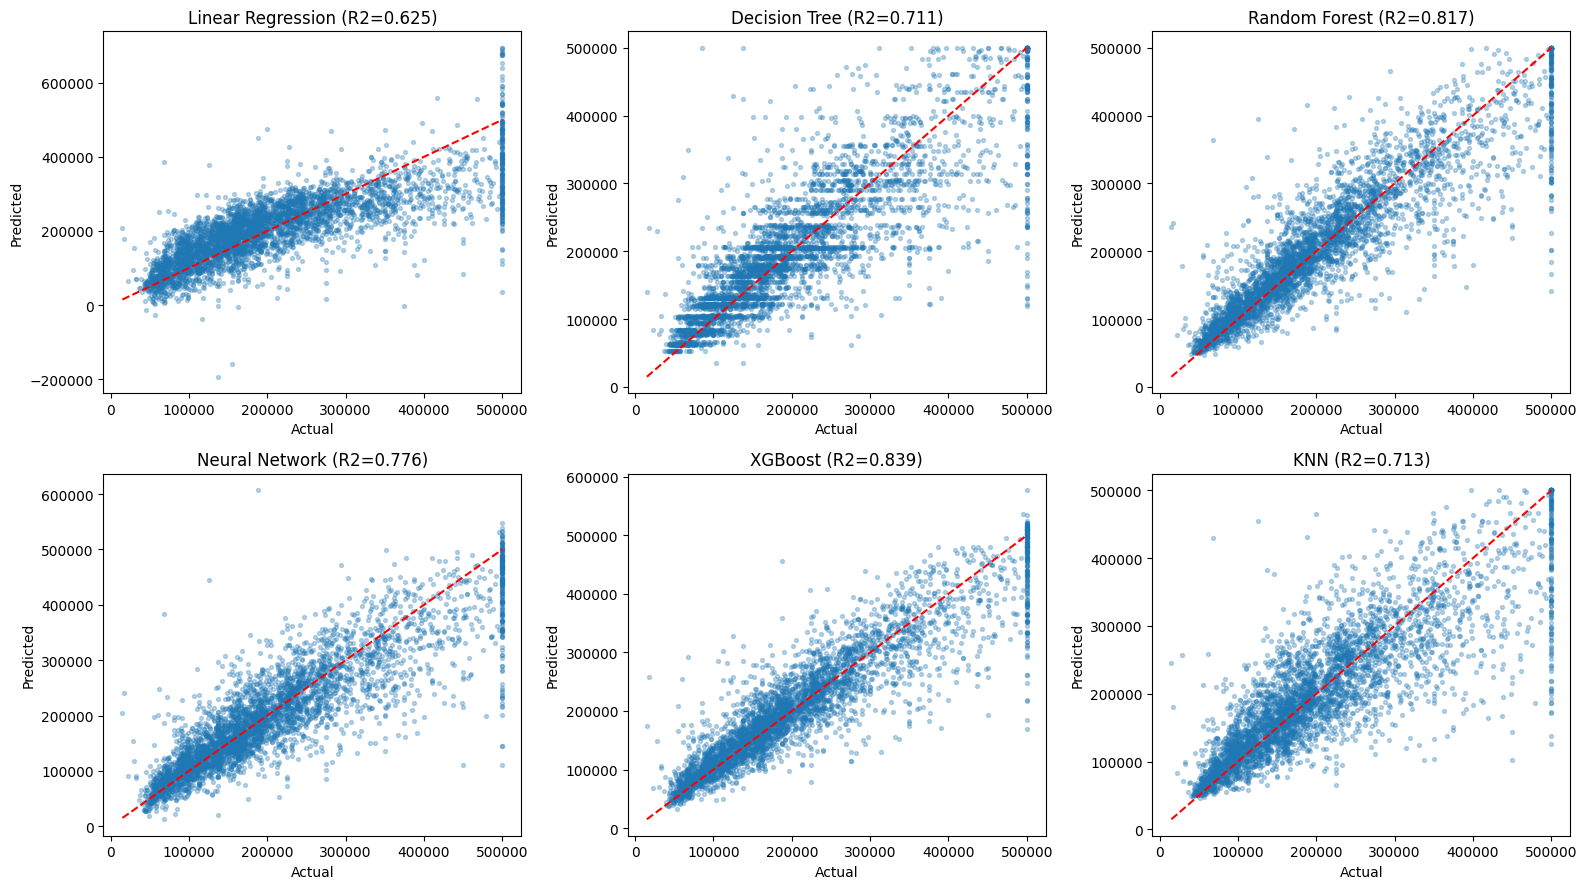

In [ ]:
res_df = pd.DataFrame(results).T.round(4).sort_values('R2', ascending=False)
display(res_df)
print(res_df.to_markdown())   # copy this output and paste it back to me

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ax.scatter(y_test, pred, alpha=0.3, s=8)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, 'r--')
    ax.set_title(f"{name} (R2={results[name]['R2']:.3f})")
    ax.set_xlabel('Actual'); ax.set_ylabel('Predicted')
plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=150)
plt.show()